# Nivell 1

## Ex1 Niv1 Preguntes analítiques directes (sense integracions complexes)

- We needed to install the mysql connector 


In [ ]:
# %pip install mysql-connector-python

📦 Imported Libraries and Their Purpose

To carry out data extraction, cleaning, analysis, and visualization, the following libraries have been imported and grouped by their specific function:

1. Data Analysis & Manipulation
* **`pandas` (`pd`)**: Core library used to structure data into tables (*DataFrames*), perform table joins (`merge`), group data (`groupby`), and calculate summary statistics.

2. Data Visualization
* **`matplotlib.pyplot` (`plt`)**: Foundational plotting library used to create, customize, and configure figure sizes, titles, and axes.
* **`seaborn` (`sns`)**: Built on top of Matplotlib, it simplifies the creation of clean, advanced statistical charts (such as *boxplots* or *line plots*) to analyze data dispersion.

3. Database Connection & Security
* **`mysql.connector`**: Official MySQL driver that connects Python directly to the database to extract tables using SQL queries.
* **`getpass`**: Allows secure password prompts via keyboard input without displaying characters on screen or hardcoding credentials in the script.


- Also need to install sqlalchemy in order to manage sql connections.

In [ ]:
# %pip install sqlalchemy pymysql

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import mysql.connector
from getpass import getpass
# import os
# import socket
# import sys


In [ ]:

connection = mysql.connector.connect(
host="localhost",
port=3306,
user="root",
# password=getpass("Password: "),
password="psw12345$",
# database="transactions"
database="sprint2db"
)

print("Connection working?:", connection.is_connected())

### Ex1.1  Com evoluciona el nombre de transaccions al llarg del temps? Exemple de passos guiats amb pandas.

Preguntes analítiques: (només utilitzant la taula de transaccions) :

In [ ]:
df_tr = pd.read_sql("SELECT * FROM transaction", connection)

    Selecciona la columna temporal adequada.
- Columna timestamp (datetime Dtype)

Preguntes analítiques: (només utilitzant la taula de transaccions) :

In [ ]:
df_tr.info()

    Defineix el nivell temporal d'anàlisi.

In [ ]:
df_tr['year'] = df_tr['timestamp'].dt.year

df_tr["year"].value_counts()


- A single transaction exists in 2026. As it represents incomplete yearly data, it was excluded from the dataframe to avoid creating columns for just one transaction in a year.

In [ ]:
df_tr = df_tr[df_tr["year"] != 2026]

- Checking any possible null dates

In [ ]:
df_tr["timestamp"].isna().sum()

    Compta el nombre de registres per període temporal.

In [ ]:
transactions_year = df_tr.groupby('year').size()
# transactions_month = df_tr.groupby('month').size()
transactions_year
# transactions_month

    Ordena els resultats cronològicament.

In [57]:
transactions_year

year
2015     9870
2016     9854
2017     9915
2018     9912
2019    10015
2020    10093
2021    10298
2022    10106
2023     9985
2024     9951
dtype: int64

    Visualitza l'evolució amb un gràfic de línies amb pandas.

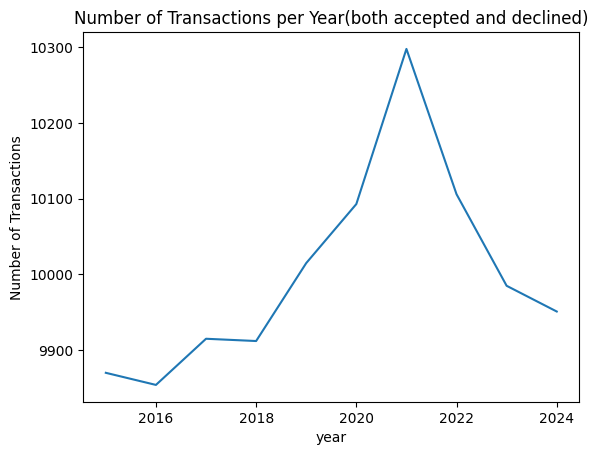

In [64]:
transactions_year.plot(kind='line')
plt.title("Number of Transactions per Year(both accepted and declined)")
plt.ylabel("Number of Transactions");
# transactions_month.plot(kind='line')

> Conclusion: The number of transactions had an increasing tendency that spiked in 2021 but went down equally until 2024

---

### Ex1.2 Niv1. Quins usuaris generen més volum de facturació? Exemple de passos guiats amb seaborn. 



    Identifica la columna que representa el usuari.
- The user is identified in the user_id column.

In [ ]:
df_tr.columns

    Agrupa les transaccions per usuari i calcula el volum total de facturació sumant la columna amount.


In [ ]:
# df_tr.groupby("user_id")["amount"].sum().reset_index()

In [ ]:
df_tr[df_tr["declined"] == 0].groupby("user_id")["amount"].sum().reset_index()

,user_id,amount
0,1,8146.82
1,10,6814.32
2,100,7888.20
3,1000,4492.88
4,1001,4768.28
...,...,...
4995,995,6364.99
4996,996,6685.46
4997,997,6169.34
4998,998,4270.64


    Ordena els usuaris de major a menor volum de facturació.


In [ ]:
df_tr[df_tr["declined"] == 0].groupby("user_id")["amount"].sum().reset_index().sort_values(by='amount', ascending=False, ignore_index=True)

,user_id,amount
0,289,47332.90
1,318,46393.44
2,455,40594.55
3,417,37393.91
4,185,34560.87
...,...,...
4995,3652,1432.29
4996,1306,1421.15
4997,1995,1405.70
4998,3119,1327.53


In [72]:
# df_tr.groupby("user_id")["amount"].sum().reset_index().sort_values(by='amount', ascending=False, ignore_index=True)

    Selecciona els N usuaris principals (per exemple, els 15 primers).
    Representa el resultat mitjançant un gràfic de barres utilitzant Seaborn


In [ ]:
group = (
    df_tr.groupby("user_id")["amount"]
    .sum()
    .reset_index()
    .sort_values(by='amount', ascending=False, ignore_index=True)
    .head(10)
)
# añadir titutlo
sns.barplot(data=group, x="user_id", y="amount", order=group["user_id"])

    Quins usuaris generen més volum de facturació?
> Based on the bar chart, the users who generate the highest billing volume (amount) are user_id 289 and user_id 318.

Here is the breakdown of the top four users in descending order:
- 289 (highest amount, near 47,000)
- 318 (close second, near 47,000)
- 455 (around 41,000)
- 417 (around 37,500)

---

### Ex1.3. Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades? Exemple de passos guiats amb seaborn.



        Crea una nova columna amb l'hora del dia a partir del timestamp.


In [ ]:
df_tr['hour'] = df_tr['timestamp'].dt.hour
# df_tr["hour"]

        Utilitza un violinplot de seaborn per analitzar la distribució dels imports.


In [ ]:
sns.violinplot(x="year", y="amount", data=df_tr, inner="quart")

> The billing amount has remained highly stable from 2015 to 2024.

        Assigna: x per l'hora del dia, y per l'import de la transacció i hue per l'estat de la transacció.


In [ ]:
df_tr.columns

In [ ]:
# check if we can use declined for hue. Must be (0,1)
df_tr["declined"].unique()


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
sns.violinplot(
    x="hour",       
    y="amount",
    hue="declined",  
    data=df_tr,
    inner="quart", split=True
)

plt.title("Distribution of amounts by hour and transaction status")
plt.show()

        Activa split per comparar acceptades i rebutjades i inner amb quartile per mostrar mediana i quartils.


In [ ]:
sns.violinplot(
    x="hour",       
    y="amount",
    hue="declined",  
    data=df_tr,
    inner="quart",
    split=False
)


> The distribution of transaction amounts is remarkably stable across all 24 hours for both approved and declined states.

    4. Quins dies de la setmana es concentra més activitat de venda?

    👉 Per a cada pregunta:

        Construeix una visualització senzilla en Python sense utilitzar IA.
        Interpreta breument el resultat obtingut.
        Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.



- My attempt: sns.countplot: Directly counts how many records (rows) exist for each day.

In [ ]:
# My attempt 
df_tr["day"] = df_tr["timestamp"].dt.day_name()

sns.countplot(
    x="day", 
    data=df_tr
)

# Using AI
# 1. Ensure datetime format and extract the day name in English (by default)
# df_tr["timestamp"] = pd.to_datetime(df_tr["timestamp"])
df_tr["day"] = df_tr["timestamp"].dt.day_name()

# 2. Define the correct chronological order for the X-axis
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

# 3. Group and count the transaction volume (activity)
group = (
    df_tr.groupby("day", observed=False)["id"]
    .count()
    .reset_index(name="total_transactions")
)

# 4. Create the basic bar chart
plt.figure(figsize=(9, 5))
sns.barplot(x="day", y="total_transactions", data=group, order=days_order)

plt.title("Sales Activity by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Number of Transactions")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


        Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.
> Both graphs indicate that the day with the highest number of sales is Thursday, but the one generated by the AI is much more readable since it sorts the days from Monday to Sunday and also adds dashed lines that help determine the transaction volume.

## Ex 2 Niv1: Preguntes analítiques complexes (amb guia)

    🌍 Context: Aquest exercici requereix combinar informació de diverses taules del model per poder respondre correctament les preguntes.

Aquí sí que serà necessari:

    » Fer merge entre taules.

    » Utilitzar groupby, pivot_table, crosstab...

    » Aplicar agregacions, transformacions intermèdies i funcions.


    Preguntes analítiques (amb guia general)


--- 
### Depenem excessivament d'un nombre reduït de països de companyies venedores?

Passos orientatius:

    1. Combinar la informació de transaccions amb la de companyies


- They are asking us to use merge. So, instead of doing an SQL JOIN query, we load the companies table separately and merge them using Python.


In [ ]:
df_co = pd.read_sql("SELECT * FROM company", connection)

- We inspect the columns in both DataFrames to determine the matching keys for the merge

In [ ]:
df_tr.info()
df_co.info()

- We will merge the data using the company_id column from the transactions dataframe and the id column from the companies dataframe.

In [ ]:
df_merged = pd.merge(
    df_tr,
    df_co,
    left_on="business_id", # sprint2db
    # left_on="company_id",  # transactions db
    right_on="id",
    how="left"
)
df_merged

    2. Agrupar la facturació per país.
    3. Calcular la facturació total generada per cada país.
    4. Ordenar els països de major a menor facturació.


In [ ]:
revenue_country = (
    df_merged.groupby("country")["amount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

revenue_country


    5. Calcular el percentatge acumulat sobre el total.

In [ ]:
#total 
revenue_total = revenue_country["amount"].sum().round(0)
# revenue_total.dtype
revenue_total

In [ ]:
revenue_country["percentage"] = (
    (revenue_country["amount"] / revenue_total) * 100).round(0)

revenue_country


    6. Visualitzar.



In [ ]:
#pandas 
# revenue_country.plot(kind='bar', x="country", y="amount", rot=90)

#visuals with seaborn
sns.barplot(
    data=revenue_country,
    x="country",
    y="amount"
    )
#display names vertically on x axis
plt.xticks(rotation=90)
plt.show()

# apuntar la unidad y si son millones o el numero comopleto

    Depenem excessivament d'un nombre reduït de països de companyies venedores?
> Yes. Five countries—Sweden, Netherlands, United Kingdom, Italy, and Germany—completely dominate the chart. Each of these individual markets generates around 4 to 5 million in transaction volume (amount).

---
### Is there seasonality in sales?

Guiding Steps

 1. Work with transaction dates.

- Ensure the DateTime column is stored in a datetime format so that Pandas `.dt` methods can be used.
  - Example: `2024-08-28 07:16:46`

 2. Extract the relevant temporal information (year and month).

- Create separate columns for the transaction year and month using the timestamp column.
- These variables will be used to identify temporal patterns and analyze seasonality.

 3. Calculate total sales volume (sum of `amount`) by year and month.

- Group transactions by year and month.
- Sum the values in the `amount` column for each year-month combination.
- This creates an aggregated table showing monthly sales revenue over time.

In [ ]:
df_tr["month"] = df_tr["timestamp"].dt.month
df_tr["year"] = df_tr["timestamp"].dt.year

In [ ]:
# Groups transactions by month and year, then calculates the total sales amount for each month-year combination. This creates a summarized table of monthly revenue over time.
sales_by_month = ( 
    df_tr.groupby(
        [df_tr["month"], df_tr["year"]]
        )["amount"]
    .sum()
    .reset_index()
)

# sales_by_month
# sales_by_month.plot(kind="bar", x="month", y="amount")

# Groups all months together across different years and sums their sales. This allows us to identify seasonal patterns and determine which months tend to generate more revenue overall.
sales_by_month_and_year = ( 
    sales_by_month.groupby(sales_by_month["month"])["amount"]
    .sum()
    .reset_index()
)


In [ ]:
# For a better readibilty, we create a dictionary in order to show month names intead of month numbers. 
month_dict = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}
# mapping the month column (number) with the dictionary
sales_by_month_and_year["month_name"] = sales_by_month_and_year["month"].map(month_dict)

# Customizes the chart by adding a title, labeling the axes, and positioning the legend in the lower-left corner for better readability.
ax = sales_by_month_and_year.plot(kind="bar", x="month_name", y="amount")
ax.set_title("Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.legend(loc="lower left")

plt.show()


In [ ]:
sales_by_month.tail()

4. Compare temporal patterns across years. Create a pivot table.
- A pivot table is useful because it places years side by side, making patterns much easier to compare.

- Create a pivot table with months as rows and years as columns.
- Fill the table with total sales amounts.
- Use the resulting table to compare monthly sales patterns across different years and identify recurring seasonal trends.

In [ ]:
pivot_table = sales_by_month.pivot_table(
    values="amount", 
    index="month", 
    columns="year"
)
pivot_table.head().style.format("{:,.0f}")

- Visualization

In [ ]:
ax = pivot_table.plot(kind="line")
ax.set_title("Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")

plt.show()


- The chart above it is not very insightful so we create a heatmap

5. Visualization with seaborn heatmap


In [ ]:
plt.figure(figsize=(12, 6))
# Using the "Blues" sequential color palette
ax = sns.heatmap(pivot_table, cmap="Blues")
ax.invert_yaxis()


> - No clear seasonality is observed in the heatmap, as high and low sales periods do not consistently occur in the same months across different years.


---
### Concentration and Variability Analysis



Option A - Product Analysis (Only if you have the products table)

**Question:** Which products generate the most revenue and with what level of variability?

Guiding Steps



1. Combine transactions, the bridge table, and products.


In [ ]:
# Importing the products table and the bridge table so we can group the amount per product
# df_pr = pd.read_sql("SELECT * FROM product", connection) #transaction db
df_pr = pd.read_sql("SELECT * FROM products", connection) #sprint2db db
df_bridge_tr_pr = pd.read_sql("SELECT * FROM transaction_products", connection)


In [ ]:
#checking name of olumns 
df_tr.columns
df_bridge_tr_pr.columns
df_pr.columns

In [ ]:
df_pr.head(5)

In [ ]:
df_merged = df_tr.merge(right=df_bridge_tr_pr, how="inner", left_on="id", right_on="transaction_id")
# 16,26,97,87 00043A49-2949-494B-A5DD-A5BAE3BB19DD
df_merged[["transaction_id", "product_id"]].head(5)
df_merged.head(5)

In [ ]:
#merge with the products table
df_merged = df_merged.merge(right=df_pr, how="inner", left_on="product_id", right_on="id")


In [ ]:
df_merged.head(2)

2. Calculate revenue per product using `groupby`, `sum`, and `sort`.


In [ ]:
revenue_x_product = df_merged.groupby(["product_id", "product_name"])["priceDollars"].sum().reset_index()

revenue_x_product = revenue_x_product.sort_values("priceDollars", ascending=False).reset_index(drop=True)

revenue_x_product = revenue_x_product.rename(
    columns={"priceDollars": "revenue"}
)

revenue_x_product

3. Select the top N products (e.g., top 5).


In [ ]:
revenue_x_product.head(10)

In [ ]:
revenue_x_product.head(10).plot(kind="bar", x="product_name", y="revenue")

4. Choose an appropriate visualization to analyze dispersion/variability.


In [ ]:
top_10_products = revenue_x_product.head(10)["product_id"]

df_top10 = df_merged[
    df_merged["product_id"].isin(top_10_products)
]
df_top10.columns

In [ ]:
product_stats = (
    df_merged.groupby("product_id")
    .agg(
        revenue=("priceDollars", "sum"),
        variability=("amount", "std")
    )
    .reset_index()
)

ax = product_stats.plot(
    kind="scatter",
    x="revenue",
    y="variability",
    figsize=(10, 6)
)

ax.set_title("Product Revenue vs Variability")
ax.set_xlabel("Revenue")
ax.set_ylabel("Variability")

plt.show()

> Data shows little relationship between a product's total revenue and its transaction variability. Maybe a slight upward trend in total spread.

---


### How Does Sales Activity Vary Across Time Slots Over the Years? (Hourly Patterns)

Guiding Steps


1. Create time slots based on the transaction hour. Use apply.


In [ ]:
def get_time_slot (hour):
    if 0 <= hour <= 5:
        return "Night"
    elif 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 17:
        return "Afternoon"
    else:
        return "Evening"

df_merged["time_slot"] = df_merged["hour"].apply(get_time_slot)


2. Build an aggregated table using `pd.crosstab()`. It counts how many occurrences there are of each time slot in each year.


In [ ]:
time_slot_crosstab = pd.crosstab(
    df_merged["time_slot"], #rows
    df_merged["year"]      #cols
)

time_slot_crosstab

3. Visualize the results with a heatmap.

In [ ]:
# 1. Define the correct chronological order
time_order = ['Morning', 'Afternoon', 'Evening', 'Night']

# 2. Reindex the DataFrame (change 'index' to 'columns' if the time slots are columns)
ordered_crosstab = time_slot_crosstab.reindex(time_order)

# 3. Plot the ordered heatmap
# ax = sns.heatmap(ordered_crosstab)
ax = sns.heatmap(
    ordered_crosstab,
    cmap='YlGnBu',      # High-contrast palette (alternatives: 'YlGnBu', 'coolwarm')
    annot=True,          # Prints the numbers directly inside the cells
    fmt='d',             # Formats numbers as integers (use '.1f' for floats)
    linewidths=0.5,      # Adds subtle grids between cells to separate colors
)
ax.set_title('Transaction Volume by Time Slot', fontsize=14, pad=15, fontweight='bold')
ax.invert_yaxis()
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.show()

---
---

# Level 2 - Relational Analysis and Advanced Patterns


## Exercise 1: Product Performance and User Acquisition Analysis

Objective

Analyze product performance by combining revenue, stability, and user acquisition metrics. The goal is to identify business risks related to:

- Excessive revenue concentration
- Dependence on recurring users
- Lack of user base growth



    Business Question: 
    Do the products generating the most revenue also drive business growth through new-user acquisition, or does the company mainly depend on recurring users repeatedly buying the same products?

Guiding Steps


### 1. Combine the necessary tables.


---
### 2. Define a **new user** criterion. A transaction is considered a user's first transaction in the system.

```python
is_new_user = True / False
```

---
### 3. Aggregate information by product and calculate:

   - Total revenue
   - Number of new users
   - Percentage of new users out of total buyers for the product

---
### 4. Create an analytical product classification, for example:

   - **Acquisition Driver**: high new-user acquisition
   - **Recurring Product**: high revenue but low acquisition
   - **Emerging Product**: low revenue but good acquisition
   - **Stagnant Product**: low revenue and low acquisition

---
### 5. Build a visualization to analyze the relationship between dimensions.

Example: Scatter Plot

- X-axis → Total revenue per product
- Y-axis → Number of new users
- Point color → Product category

Important Note

The goal is not only to show charts, but to interpret the business implications of failing to attract new users.

---



 ## Exercise 2: Company–User Geographic Analysis and Expansion Opportunities

Objective

Analyze the relationship between:

- Seller company country
- User residence country
- Purchasing flows between countries

Business Question

Is the business mainly driven by local markets (same user-country and company-country), or is there a genuine international expansion opportunity by opening more companies in specific countries?

Guiding Steps

1. Combine the necessary tables.
2. Create a key analysis variable:

```python
local_purchase = True / False
```

3. Analyze overall behavior:

   - Percentage of local vs international transactions
   - Percentage of local vs international revenue

4. User-country analysis:

For each user country calculate:

- Percentage of purchases from companies in the same country
- Percentage of purchases from foreign companies
- Total purchase amount

5. Company-country analysis:

For each company country calculate what percentage of revenue comes from:

- Local users
- Foreign users

6. Choose a visualization that clearly explains the phenomenon.

7. Strategic interpretation:

- In which countries would it make sense to open more local companies?
- Are there countries with demand but limited local supply?
- Is the business overly dependent on companies from a single country?
- Would opening local companies reduce friction or improve conversion?

---

Level 3 - Executive Visualization and Storytelling

Exercise 1: Department Mini Dashboard

Objective

Build a mini dashboard in Python using Google Colab.

The recommended option is:

Option 1 - Single Figure with Subplots (Recommended)

Build one figure containing 4 subplots 